# Assignment 1
## Ákos Kappel

This jupyter notebook was used for experimenting with different techniques for image processing. The code is not very clean. Better version are available in notebooks: *[beer_bubbles.ipynb](beer_bubbles.ipynb)*, *[breast_cancer.ipynb](breast_cancer.ipynb)*

### Techniques

**Filtering**
- mean
- median
- gaussian
- bilateral

**Edge detection**
- sobel
- laplacian
- canny

**Thresholding**
- otsu
- adaptive

**Sharpening**


In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
def show_images(images):
    for name, image in images:
        cv.imshow(name, image)
    cv.waitKey(0)
    cv.destroyAllWindows()


class GaussianTracker:
    def __init__(self, image, ksize=0, sigmaX=0, window='image', trackbar='ksize'):
        self.img = image
        self.ksize = ksize
        self.sigmaX = sigmaX
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.ksize, 100, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.ksize = cv.getTrackbarPos(self.trackbar, self.window)
        if self.ksize % 2 == 0:
            self.ksize += 1
        blur = cv.GaussianBlur(self.img, (self.ksize, self.ksize), self.sigmaX)
        cv.imshow(self.window, blur)


class MedianTracker:
    def __init__(self, image, ksize=0, window='image', trackbar='ksize'):
        self.img = image
        self.ksize = ksize
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.ksize, 100, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.ksize = cv.getTrackbarPos(self.trackbar, self.window)
        if self.ksize % 2 == 0:
            self.ksize += 1
        blur = cv.medianBlur(self.img, self.ksize)
        cv.imshow(self.window, blur)


class BilateralTracker:
    def __init__(self, image, d=0, sigmaColor=0, sigmaSpace=0, window='image', trackbar='d'):
        self.img = image
        self.d = d
        self.sigmaColor = sigmaColor
        self.sigmaSpace = sigmaSpace
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.d, 100, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.d = cv.getTrackbarPos(self.trackbar, self.window)
        blur = cv.bilateralFilter(self.img, self.d, self.sigmaColor, self.sigmaSpace)
        cv.imshow(self.window, blur)


class GlobalThresholdTracker:
    def __init__(self, image, original=None, thresh=0, maxval=255, type=cv.THRESH_BINARY, use_mask=True, window='image',
                 trackbar='threshold'):
        self.img = image
        self.original = original
        self.thresh = thresh
        self.maxval = maxval
        self.type = type
        self.use_mask = use_mask
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.thresh, self.maxval, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.thresh = cv.getTrackbarPos(self.trackbar, self.window)
        ret, thresh = cv.threshold(self.img, self.thresh, self.maxval, self.type)
        if self.use_mask:
            mask = cv.bitwise_not(thresh)
            img = self.img if self.original is None else self.original
            thresh = cv.bitwise_and(img, img, mask=mask)
        cv.imshow(self.window, thresh)


class AdaptiveThresholdTracker:
    def __init__(self, image, ksize=11, type=cv.ADAPTIVE_THRESH_GAUSSIAN_C, window='image', trackbar='threshold'):
        self.img = image
        self.ksize = ksize
        self.type = type
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.ksize, 255, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.ksize = cv.getTrackbarPos(self.trackbar, self.window)
        if self.ksize % 2 == 0:
            self.ksize += 1
        if self.ksize < 3:
            self.ksize = 3
        adaptive = cv.adaptiveThreshold(self.img, 255, self.type, cv.THRESH_BINARY, self.ksize, 2)
        cv.imshow(self.window, adaptive)


class CannyTracker:
    def __init__(self, image, threshold1=0, threshold2=0, window='image', trackbar1='threshold1',
                 trackbar2='threshold2'):
        self.img = image
        self.threshold1 = threshold1
        self.threshold2 = threshold2
        self.window = window
        self.trackbar1 = trackbar1
        self.trackbar2 = trackbar2
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar1, self.window, self.threshold1, 255, self.update)
        cv.createTrackbar(self.trackbar2, self.window, self.threshold2, 255, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.threshold1 = cv.getTrackbarPos(self.trackbar1, self.window)
        self.threshold2 = cv.getTrackbarPos(self.trackbar2, self.window)
        if self.threshold1 > self.threshold2:
            self.threshold1, self.threshold2 = self.threshold2, self.threshold1
        canny = cv.Canny(self.img, self.threshold1, self.threshold2)
        cv.imshow(self.window, canny)


class ContourSizeTracker:
    def __init__(self, image, min_area=0, max_area=10_000, mode=cv.RETR_TREE, window='image', trackbar='area'):
        self.img = image
        self.min_area = min_area
        self.max_area = max_area
        self.mode = mode
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.min_area, self.max_area, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.min_area = cv.getTrackbarPos(self.trackbar, self.window)
        contours, hierarchy = cv.findContours(self.img, self.mode, cv.CHAIN_APPROX_SIMPLE)
        contours = [c for c in contours if self.min_area < cv.contourArea(c) < self.max_area]
        img_copy = img.copy()
        img_copy = cv.drawContours(img_copy, contours, -1, (255, 0, 0), 2)
        cv.imshow(self.window, img_copy)


class WatershedTracker:
    def __init__(self, image, dist=0, window='image', trackbar='threshold'):
        self.img = image
        self.dist = dist
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.dist, 100, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.dist = cv.getTrackbarPos(self.trackbar, self.window) / 100

        # red channel
        r = self.img[:, :, 2]

        # Otsu's thresholding
        ret, otsu = cv.threshold(r, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

        # morphological operations
        kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
        opening = cv.morphologyEx(otsu, cv.MORPH_OPEN, kernel, iterations=2)

        # find sure background area
        sure_bg = cv.dilate(opening, kernel, iterations=5)

        # distance transform
        dist = cv.distanceTransform(opening, cv.DIST_L2, 5)
        cv.normalize(dist, dist, 0, 1.0, cv.NORM_MINMAX)

        # find sure foreground area
        ret, sure_fg = cv.threshold(dist, self.dist * dist.max(), 255, 0)

        # find unknown region
        sure_fg = np.uint8(sure_fg)
        unknown = cv.subtract(sure_bg, sure_fg)

        # marker labelling
        ret, markers = cv.connectedComponents(sure_fg)

        markers = markers + 1
        markers[unknown == 255] = 0

        # watershed
        markers = cv.watershed(self.img, markers)
        ws = self.img.copy()
        ws[markers == -1] = [255, 0, 0]
        markers = markers.astype(np.uint8)

        cv.imshow(self.window, ws)
        cv.imshow(self.window + ' markers', markers)

In [3]:
file1 = 'images/TCGA-18-5592-01Z-00-DX1.tif'
file2 = 'images/pena.tif'
file3 = 'images/img (5).png'

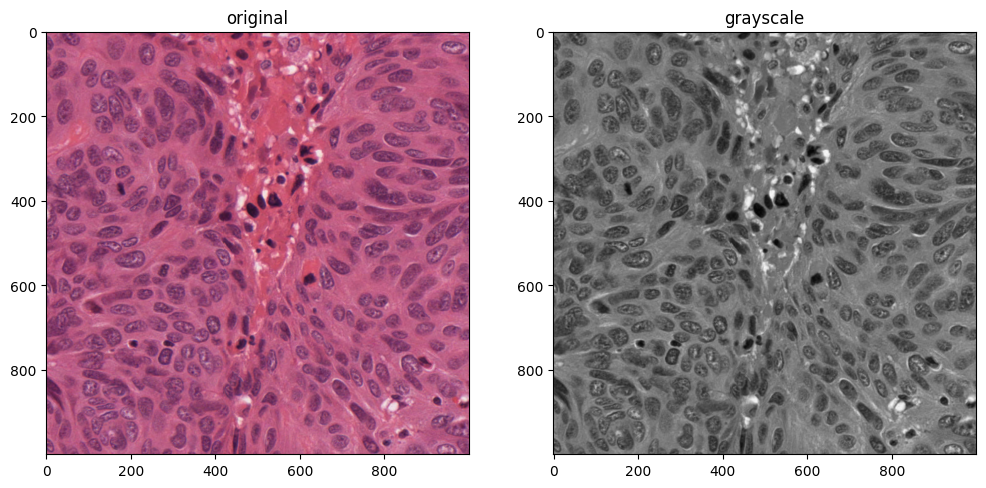

In [4]:
# load image
img = cv.imread(file1)

org_img = img.copy()

# convert to grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# convert to rgb
rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# split channels
b, g, r = cv.split(img)

# show images
plt.figure(figsize=(12, 12))
plt.subplot(1, 2, 1)
plt.title('original')
plt.imshow(rgb_img)
plt.subplot(1, 2, 2)
plt.title('grayscale')
plt.imshow(gray, cmap='gray')
plt.show()

In [5]:
rg = cv.subtract(r, g)

# threshold
ret, rg_thresh = cv.threshold(rg, 75, 255, cv.THRESH_BINARY_INV)

# opening
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(rg_thresh, cv.MORPH_OPEN, kernel, iterations=2)

# closing
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
closing = cv.morphologyEx(opening, cv.MORPH_CLOSE, kernel, iterations=2)

# apply mask
masked = cv.bitwise_and(img, img, mask=closing)

# show images
# show_images([
#     ('Original', img),
#     ('Red - Green', rg),
#     ('Red - Green Threshold', rg_thresh),
#     ('Opening', opening),
#     ('Closing', closing),
#     ('Masked', masked),
# ])

In [42]:
# GlobalThresholdTracker(gray, window='gray')
# GlobalThresholdTracker(r, window='red', thresh=160)
# GlobalThresholdTracker(g, window='green', thresh=60)
# GlobalThresholdTracker(b, window='blue', thresh=100)

In [6]:
# blur
blur = cv.medianBlur(img, 5)
b, g, r = cv.split(blur)

# threshold red channel
ret, r_thresh = cv.threshold(r, 180, 255, cv.THRESH_BINARY)

# subtract red channel from original image
sub = cv.subtract(r, r_thresh)

# opening
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(sub, cv.MORPH_OPEN, kernel, iterations=2)

# closing
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
closing = cv.morphologyEx(opening, cv.MORPH_CLOSE, kernel, iterations=1)

# show_images([
#     ('image', img),
#     ('r_thresh', r_thresh),
#     ('sub', sub),
#     ('opening', opening),
#     ('closing', closing),
# ])
# GlobalThresholdTracker(r, window='red', original=img, thresh=160)

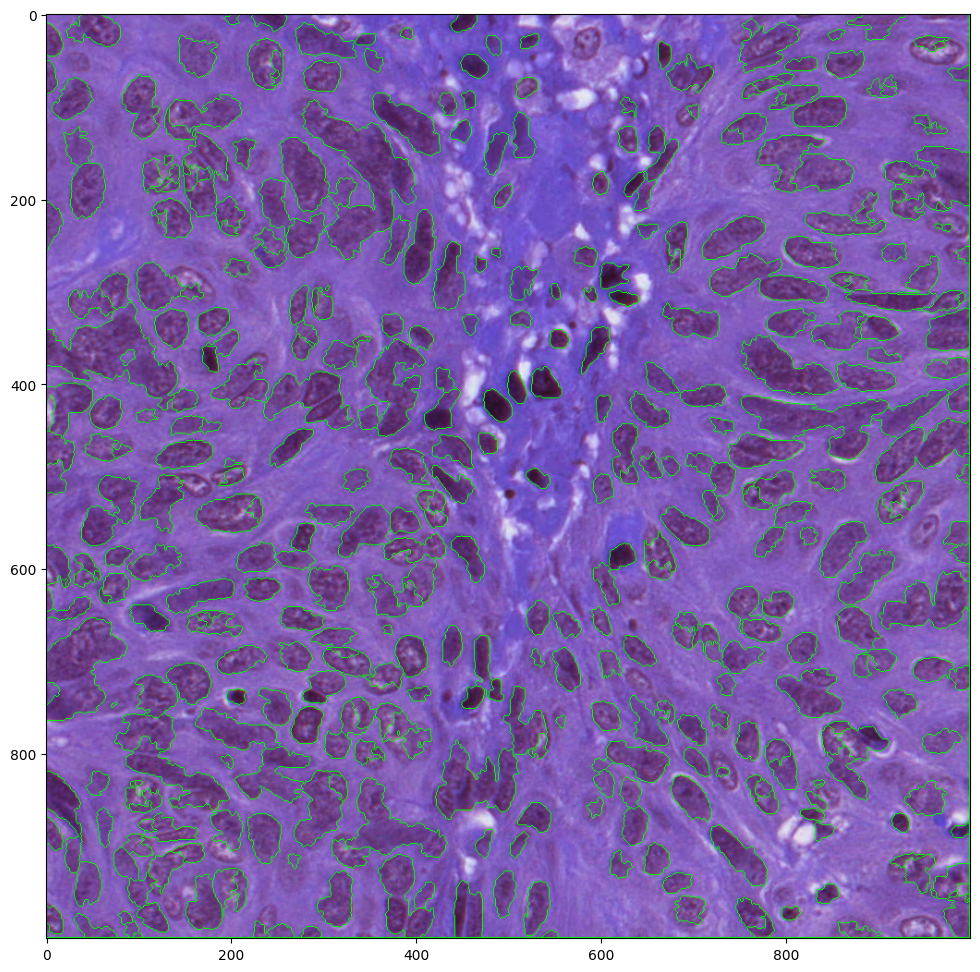

In [47]:
# Otsu's thresholding
ret, otsu = cv.threshold(r, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

# morphological operations
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(otsu, cv.MORPH_OPEN, kernel, iterations=2)

# find sure background area
sure_bg = cv.dilate(opening, kernel, iterations=5)

# distance transform
dist = cv.distanceTransform(opening, cv.DIST_L2, 5)
cv.normalize(dist, dist, 0, 1.0, cv.NORM_MINMAX)

# find sure foreground area
ret, sure_fg = cv.threshold(dist, 0.2 * dist.max(), 255, 0)

# find unknown region
sure_fg = np.uint8(sure_fg)
unknown = cv.subtract(sure_bg, sure_fg)

# marker labelling
ret, markers = cv.connectedComponents(sure_fg)

markers = markers + 1
markers[unknown == 255] = 0

# watershed
markers = cv.watershed(img, markers)
ws = img.copy()
ws[markers == -1] = [0, 255, 0]
markers2 = markers.astype(np.uint8)

# show_images([
#     ('otsu', otsu),
#     ('opening', opening),
#     ('sure_bg', sure_bg),
#     ('dist', dist),
#     ('sure_fg', sure_fg),
#     ('unknown', unknown),
#     ('markers', markers2),
#     ('ws', ws),
# ])
plt.figure(figsize=(12, 12))
plt.imshow(ws)

In [48]:
seg_img = np.zeros_like(img)

white = [255, 255, 255]
black = [0, 0, 0]

# set edges to white and interior to black
seg_img[markers == -1] = white
seg_img[markers != -1] = black

# set image sides to black
seg_img[0, :] = black
seg_img[-1, :] = black
seg_img[:, 0] = black
seg_img[:, -1] = black

# convert to grayscale
seg_img = cv.cvtColor(seg_img, cv.COLOR_BGR2GRAY)

# count contours
contours, _ = cv.findContours(seg_img, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

# draw contours
tmp = img.copy()
cv.drawContours(tmp, contours, -1, (0, 255, 0), 2)

num_cells = len(contours)
print(f'Number of cells: {num_cells}')

show_images([
    ('img', img),
    ('seg_img', seg_img),
    ('tmp', tmp),
])

Number of cells: 253


In [51]:
# closing
ret, thresh = cv.threshold(r, 160, 255, cv.THRESH_BINARY_INV)
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel, iterations=3)

show_images([
    ('thresh', thresh),
    ('closing', closing),
    ('opening', opening),
])

number of contours: 299
[103.0, 103.0, 104.0, 110.0, 117.0, 121.5, 128.5, 132.5, 133.5, 136.0] [3894.5, 4502.5, 5205.0, 5364.0, 5955.5, 6230.0, 6254.0, 7034.5, 7580.0, 7655.0]


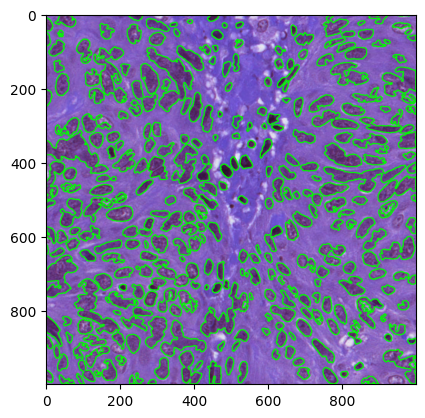

In [53]:
# contours
contours, _ = cv.findContours(opening, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
contours = [c for c in contours if cv.contourArea(c) > 100]
print(f'number of contours: {len(contours)}')
sizes = list(sorted([cv.contourArea(c) for c in contours]))
print(sizes[:10], sizes[-10:])

img_copy = cv.drawContours(img.copy(), contours, -1, (0, 255, 0), 2)
plt.imshow(img_copy, cmap='gray')

show_images([
    ('original image', org_img),
    ('contours image', img_copy),
    ('thresh image', thresh),
    ('opening', opening),
    ('closing', closing),
])

In [60]:
# count number of connected components
ret, labels = cv.connectedComponents(opening)

print(labels.shape, ret)

# label image
label_hue = np.uint8(179 * labels / np.max(labels))
blank_ch = 255 * np.ones_like(label_hue)
labeled_img = cv.merge([label_hue, blank_ch, blank_ch])

# convert to BGR for display
labeled_img = cv.cvtColor(labeled_img, cv.COLOR_HSV2BGR)

# set bg label to black
labeled_img[label_hue == 0] = 0

num_components = np.max(labels)
print(f'Number of components: {num_components}')

show_images([
    ('original image', org_img),
    ('labeled image', labeled_img),
])

(1000, 1000) 379
Number of components: 378


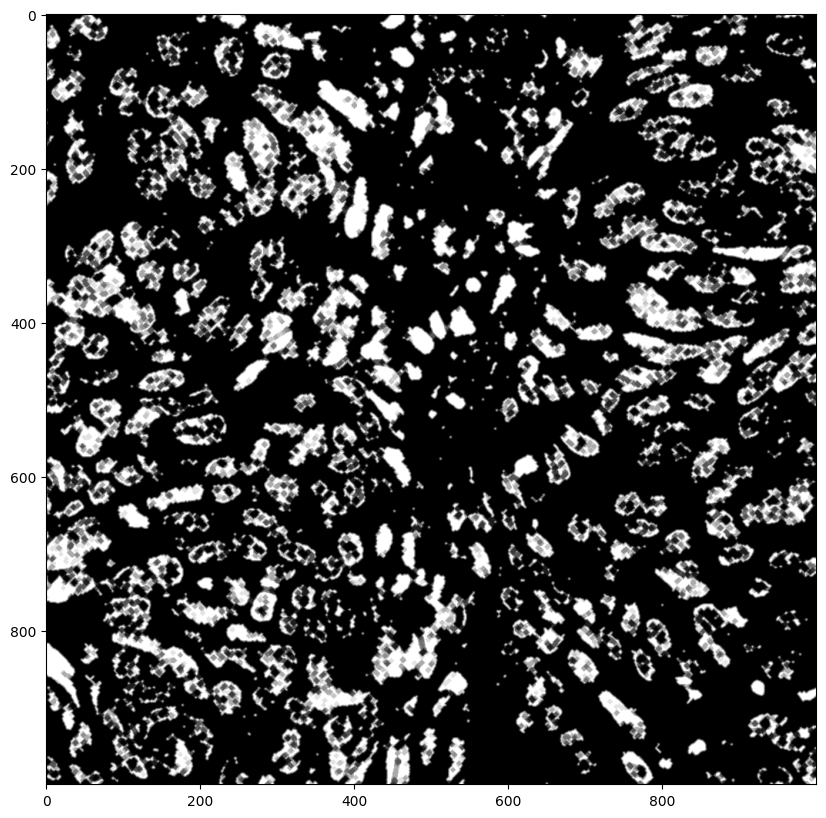

In [33]:
# sharpen image
kernel = np.array([[-1, -1, -1],
                   [-1, 9, -1],
                   [-1, -1, -1]])
sharpened = cv.filter2D(gray, -1, kernel)

# threshold sharpened image
ret, thresh = cv.threshold(sharpened, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

# morphological opening
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel, iterations=2)

# blur
blurred = cv.blur(opening, (3, 3))

# morphological closing
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
closing = cv.morphologyEx(blurred, cv.MORPH_CLOSE, kernel, iterations=2)

# dilate image
kernel = np.ones((3, 3), np.uint8)
dilated = cv.dilate(closing, kernel, iterations=1)

# erode image
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
eroded = cv.erode(closing, kernel, iterations=1)

show_images([
    ('original image', org_img),
    ('sharpened image', sharpened),
    ('thresh image', thresh),
    ('opening', opening),
    ('blurred', blurred),
    ('closing', closing),
    ('dilated', dilated),
    ('eroded', eroded),
])

plt.figure(figsize=(10, 10))
plt.imshow(eroded, cmap='gray')

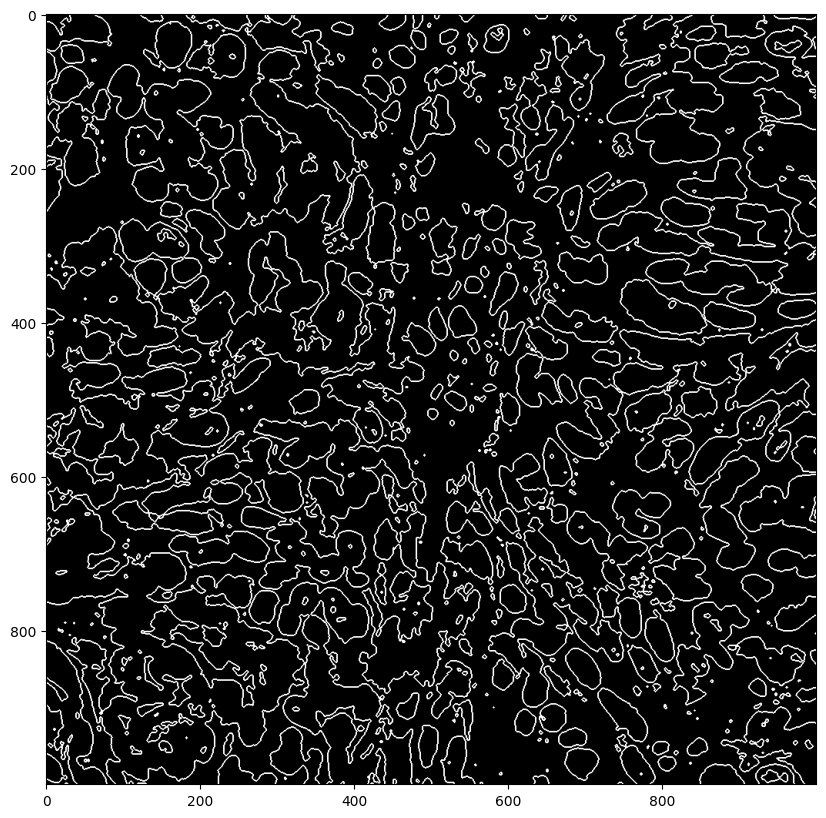

In [9]:
# morphological gradient
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
gradient = cv.morphologyEx(r_thresh, cv.MORPH_GRADIENT, kernel)

plt.figure(figsize=(10, 10))
plt.imshow(gradient, cmap='gray')